# Pipeline complet — Comparaison de tous les modèles de régression par validation croisée
**Un seul notebook** : il lance, de bout en bout, la comparaison de toutes les méthodes (de la MCO au boosting) en **validation croisée à 10 blocs**, puis produit les résultats (tableau, graphiques, fichiers).

**Modèles comparés** (mêmes blocs de validation croisée pour tous, donc MSE comparables) :

| Famille | Colonnes de `PREV` |
|---|---|
| Moindres carrés | `MCO`, `BIC` (sélection backward/both par BIC), `AIC` (idem par AIC) |
| Pénalisation | `lasso`, `elastic` (ElasticNet), `ridge` (RidgeCV), `ridgeGS` (Ridge + GridSearchCV) |
| Réduction de dimension | `pcr`, `pls` |
| Forêt aléatoire | `foret` |
| Boosting | `gbm1`, `gbm2` (gradient boosting, profondeur 1 / 2), `gbms1`, `gbms2` (stochastic, `subsample=0.2`), `cat` (CatBoost) |

**Étapes** : 1. configuration → 2. données et matrice de design → 3. validation croisée de tous les modèles → 4. résultats (métriques, graphiques, hyperparamètres choisis par bloc, test final optionnel) → 5. export des fichiers.

**Test final (optionnel)** : avec `TAILLE_TEST_FINAL > 0` (ex. `0.2`), une part des données est mise de côté **avant** la validation croisée. La validation croisée compare les méthodes sur le reste ; chaque modèle est ensuite réajusté sur tout ce reste et évalué **une seule fois** sur ce test final (section 4.4). Par défaut (`0.0`), il n'y a pas de test final : les prédictions hors échantillon de la validation croisée servent d'évaluation.

Prérequis : `scikit-learn`, `pandas`, `numpy`, `matplotlib`, `patsy` ; `catboost` (optionnel, sinon `cat` est ignoré) ; `ols_step_sk.py` dans le même dossier (pour BIC/AIC).

## 1. Configuration

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from patsy import dmatrix

from sklearn.linear_model import LinearRegression, Ridge, LassoCV, ElasticNetCV, RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, GridSearchCV, train_test_split
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

try:
    from catboost import CatBoostRegressor
except ImportError:
    CatBoostRegressor = None
    print("catboost non installé (pip install catboost) : la méthode 'cat' sera ignorée")

try:
    import ols_step_sk
except ImportError:
    ols_step_sk = None
    print("ols_step_sk.py introuvable : BIC et AIC seront ignorés")

# ← Paramètres à modifier
URL_DONNEES = "https://regression-avec-python.github.io/donnees/ozone_transf.txt"
NOM_Y = "maxO3"          # variable à prédire (renommée Y)
ESPACE = "X"             # espace des variables : "X" (base), "XI" (interactions), "XP" (polynômes 2-3), "XIP" (les deux)
NB_BLOCS = 10            # nombre de blocs de la validation croisée
GRAINE_BLOCS = 1234      # graine du tirage des blocs
GRAINE_CV = 0            # graine des KFold internes (choix des hyperparamètres)
GRAINE = 42              # graine de tous les modèles et découpages aléatoires (résultats reproductibles)
CALCULER_IC = True       # BIC / AIC : rapide avec "X", très long avec XI / XIP
TAILLE_TEST_FINAL = 0.0  # part d'un échantillon de test final, mis de côté AVANT la validation croisée (0 = pas de test final)
GRAINE_TEST = 2024       # graine du tirage de l'échantillon de test final
N_BOOT_IC = 1000         # rééchantillonnages pour les intervalles de confiance du MSE de test
DOSSIER_SORTIE = "./"    # dossier où écrire les fichiers résultats

# Option pour tester le code rapidement : n'utilise qu'une fraction des lignes, tirées au hasard.
# Les résultats n'ont alors aucune valeur ; les fichiers sont écrits dans test_pipeline/ pour ne rien écraser.
MODE_TEST = False        # True pour activer le mode test
FRACTION_TEST = 0.10     # part des lignes conservées en mode test
GRAINE_ECHANTILLON = 2025   # graine du tirage des lignes
if MODE_TEST:
    DOSSIER_SORTIE = "test_pipeline/"
    os.makedirs(DOSSIER_SORTIE, exist_ok=True)
    print(f"MODE TEST : {FRACTION_TEST:.0%} des lignes, résultats écrits dans {DOSSIER_SORTIE}")

## 2. Données et matrice de design

In [2]:
don = pd.read_csv(URL_DONNEES, header=0, sep=";", index_col=0)
don.rename(columns={NOM_Y: "Y"}, inplace=True)
if MODE_TEST:
    don = don.sample(frac=FRACTION_TEST, random_state=GRAINE_ECHANTILLON).sort_index()
print(don.shape)

nomsvar = list(don.columns.difference(["Y"]))
print("Variables explicatives :", nomsvar)

# Variables qualitatives codées en dummies par patsy (la colonne intercept est retirée)
X_base = np.asarray(dmatrix("~" + "+".join(nomsvar), don))[:, 1:]
espaces = {"X": X_base}
if ESPACE in ("XI", "XIP"):
    XI = np.asarray(dmatrix("1 + (" + "+".join(nomsvar) + ")**2", don))[:, 1:]    # interactions deux à deux
    espaces["XI"] = XI
if ESPACE in ("XP", "XIP"):
    XP = np.concatenate((X_base, X_base**2, X_base**3), axis=1)                  # polynômes degrés 2 et 3
    espaces["XP"] = XP
if ESPACE == "XIP":
    espaces["XIP"] = np.concatenate((XI, XP), axis=1)

X = espaces[ESPACE]
Y = don["Y"].to_numpy()
print(f"Espace {ESPACE} : {X.shape[0]} observations x {X.shape[1]} variables")

# Échantillon de test final (optionnel) : mis de côté avant toute validation croisée, jamais utilisé pour choisir un modèle ou un réglage
est_test = np.zeros(len(Y), dtype=bool)
if TAILLE_TEST_FINAL > 0:
    _, idx_test = train_test_split(np.arange(len(Y)), test_size=TAILLE_TEST_FINAL, random_state=GRAINE_TEST)
    est_test[idx_test] = True
    print(f"Test final : {est_test.sum()} observations mises de côté ; validation croisée sur {(~est_test).sum()} observations")

(1366, 22)
Variables explicatives : ['Ne12', 'Ne15', 'Ne18', 'Ne6', 'Ne9', 'T12', 'T15', 'T18', 'T6', 'T9', 'Vx12', 'Vx15', 'Vx18', 'Vx6', 'Vx9', 'Vy12', 'Vy15', 'Vy18', 'Vy6', 'Vy9', 'maxO3v']
Espace X : 1366 observations x 21 variables


## 3. Validation croisée de tous les modèles
Chaque observation est affectée à un bloc ; pour chaque bloc, on apprend sur les autres blocs et on prédit le bloc mis de côté. À la fin, `PREV` contient pour chaque observation une prédiction **hors échantillon** par méthode.

In [3]:
n_cv = int((~est_test).sum())                    # observations utilisées pour la validation croisée
tmp = np.arange(n_cv) % NB_BLOCS
rng = np.random.default_rng(seed=GRAINE_BLOCS)
bloc = np.full(len(Y), -1)                       # -1 = échantillon de test final
bloc[~est_test] = rng.choice(tmp, size=n_cv, replace=False)

PREV = pd.DataFrame({"bloc": bloc, "Y": Y}, index=don.index)
params_cv = {}                     # hyperparamètres choisis par bloc (lambda, nb de composantes, nb d'itérations...)
params_test = {}                   # hyperparamètres du modèle final (ajusté sur toute la partie validation croisée)
temps = {}                         # temps de calcul cumulé par méthode (s)
tache = None                       # bloc en cours, ou "test" pour l'ajustement final

kf = KFold(n_splits=10, shuffle=True, random_state=GRAINE_CV)       # validation interne des méthodes pénalisées
kfaxes = KFold(n_splits=4, shuffle=True, random_state=GRAINE_CV)    # validation interne pour PCR / PLS (plus stable)
nbaxes = 20                                                  # nb max de composantes testées (1 à 19)

configs_gbm = {
    "gbm1":  dict(n_estimators=1000, max_depth=1, learning_rate=0.1),
    "gbm2":  dict(n_estimators=1000, max_depth=2, learning_rate=0.1),
    "gbms1": dict(n_estimators=5000, max_depth=1, learning_rate=0.1, subsample=0.2),
    "gbms2": dict(n_estimators=5000, max_depth=2, learning_rate=0.1, subsample=0.2),
}


def enregistrer(nom, masque, prediction, t0, **hyper):
    """Stocke la prédiction du bloc, le temps de calcul et les hyperparamètres retenus."""
    if nom not in PREV.columns:
        PREV[nom] = 0.0
    PREV.loc[masque, nom] = np.ravel(prediction)
    if tache == "test":
        params_test.update(hyper)
        return
    temps[nom] = temps.get(nom, 0.0) + time.time() - t0
    for k, v in hyper.items():
        params_cv.setdefault(k, []).append(v)


def selection_ic(crit, Xapp, Yapp):
    modele = ols_step_sk.LinearRegressionSelectionFeatureIC(verbose=0, crit=crit)
    if not hasattr(modele, "tol"):         # compatibilité avec les versions récentes de scikit-learn
        modele.tol = 1e-6
    return modele.fit(X=Xapp, y=Yapp)


for tache in list(range(NB_BLOCS)) + (["test"] if est_test.any() else []):
    if tache == "test":
        print("Ajustement final sur toute la partie validation croisée -> prédiction du test final")
        test = est_test
    else:
        print(f"Bloc {tache + 1}/{NB_BLOCS}")
        test = (bloc == tache)
    app = ~est_test & ~test
    Xapp, Xtest, Yapp = X[app], X[test], Y[app]

    # --- MCO
    t0 = time.time()
    enregistrer("MCO", test, LinearRegression().fit(Xapp, Yapp).predict(Xtest), t0)

    # --- BIC / AIC (sélection de variables pas à pas)
    if CALCULER_IC and ols_step_sk is not None:
        for crit in ("bic", "aic"):
            t0 = time.time()
            m = selection_ic(crit, Xapp, Yapp)
            enregistrer(crit.upper(), test, m.predict(Xtest), t0, **{f"nb_var_{crit.upper()}": len(m.selected_features_)})

    # --- Lasso (le chemin de lambdas est réutilisé pour le ridge)
    t0 = time.time()
    pipe_lasso = Pipeline([("cr", StandardScaler()), ("lassocv", LassoCV(cv=kf, random_state=GRAINE))]).fit(Xapp, Yapp)
    etape_lasso = pipe_lasso.named_steps["lassocv"]
    enregistrer("lasso", test, pipe_lasso.predict(Xtest), t0, lambda_lasso=etape_lasso.alpha_)

    # --- ElasticNet
    t0 = time.time()
    pipe_enet = Pipeline([("cr", StandardScaler()), ("enetcv", ElasticNetCV(cv=kf, max_iter=10000, random_state=GRAINE))]).fit(Xapp, Yapp)
    enregistrer("elastic", test, pipe_enet.predict(Xtest), t0)

    # --- Ridge : RidgeCV puis GridSearchCV, sur une grille = 100 x chemin du lasso
    alphas_ridge = 100 * etape_lasso.alphas_
    t0 = time.time()
    pipe_ridge = Pipeline([("cr", StandardScaler()), ("ridgecv", RidgeCV(cv=kf, alphas=alphas_ridge))]).fit(Xapp, Yapp)
    enregistrer("ridge", test, pipe_ridge.predict(Xtest), t0)

    t0 = time.time()
    cv_ridge = GridSearchCV(Pipeline([("cr", StandardScaler()), ("ridge", Ridge(random_state=GRAINE))]),
                            {"ridge__alpha": alphas_ridge}, cv=kf,
                            scoring="neg_mean_squared_error", n_jobs=3).fit(Xapp, Yapp)
    enregistrer("ridgeGS", test, cv_ridge.predict(Xtest), t0)

    # --- Forêt aléatoire
    t0 = time.time()
    enregistrer("foret", test, RandomForestRegressor(random_state=GRAINE).fit(Xapp, Yapp).predict(Xtest), t0)

    # --- PCR : ACP puis MCO ; PLS : composantes construites avec Y. Nb de composantes choisi par CV (4 blocs)
    t0 = time.time()
    pipe_pcr = Pipeline([("cr", StandardScaler()), ("acp", PCA(random_state=GRAINE)), ("reg", LinearRegression())])
    cv_pcr = GridSearchCV(pipe_pcr, {"acp__n_components": list(range(1, nbaxes))}, cv=kfaxes,
                          scoring="neg_mean_squared_error", n_jobs=3).fit(Xapp, Yapp)
    enregistrer("pcr", test, cv_pcr.predict(Xtest), t0, nb_comp_pcr=cv_pcr.best_params_["acp__n_components"])

    t0 = time.time()
    cv_pls = GridSearchCV(PLSRegression(), {"n_components": list(range(1, nbaxes))}, cv=kfaxes,
                          scoring="neg_mean_squared_error", n_jobs=3).fit(Xapp, Yapp)
    enregistrer("pls", test, cv_pls.predict(Xtest), t0, nb_comp_pls=cv_pls.best_params_["n_components"])

    # --- Gradient boosting (early stopping sur 10 % de l'apprentissage) et stochastic gradient boosting
    for nom, params in configs_gbm.items():
        t0 = time.time()
        gbm = GradientBoostingRegressor(**params, random_state=GRAINE, validation_fraction=0.1,
                                        n_iter_no_change=10).fit(Xapp, Yapp)
        enregistrer(nom, test, gbm.predict(Xtest), t0, **{f"nb_iter_{nom}": gbm.n_estimators_})

    # --- CatBoost : early stopping sur UN échantillon de validation (10 % de l'apprentissage), pas par validation croisée
    if CatBoostRegressor is not None:
        t0 = time.time()
        X_tr, X_va, y_tr, y_va = train_test_split(Xapp, Yapp, test_size=0.1, random_state=GRAINE)
        cat = CatBoostRegressor(iterations=5000, learning_rate=0.1, subsample=0.1, loss_function="RMSE",
                                random_seed=GRAINE, verbose=0)
        cat.fit(X_tr, y_tr, eval_set=(X_va, y_va), early_stopping_rounds=10)
        enregistrer("cat", test, cat.predict(Xtest), t0, nb_iter_cat=cat.get_best_iteration())

methodes = [c for c in PREV.columns if c not in ("bloc", "Y")]
print(f"\nTerminé : {len(methodes)} méthodes -> {methodes}")

# À partir d'ici, PREV ne contient que les observations de la validation croisée ; le test final est à part
PREV_test = PREV[est_test].copy()
PREV = PREV[~est_test]

Bloc 1/10


Bloc 2/10


Bloc 3/10


Bloc 4/10


Bloc 5/10


...

Bloc 7/10


Bloc 8/10


Bloc 9/10


Bloc 10/10



Terminé : 15 méthodes -> ['MCO', 'BIC', 'AIC', 'lasso', 'elastic', 'ridge', 'ridgeGS', 'foret', 'pcr', 'pls', 'gbm1', 'gbm2', 'gbms1', 'gbms2', 'cat']


## 4. Résultats
### 4.1 Tableau des performances (validation croisée)
- **MSE** : moyenne des erreurs² (pénalise les grosses erreurs) — critère de classement
- **RMSE** : √MSE, dans l'unité de Y
- **MAE** : moyenne des |erreurs|, plus robuste aux valeurs extrêmes
- **R2_cv** : 1 − MSE / variance de Y (part de variance expliquée hors échantillon)
- **Gain_vs_MCO** : variation relative du MSE par rapport aux MCO (négatif = mieux que MCO)

In [4]:
famille = {"MCO": "Moindres carrés", "BIC": "Moindres carrés", "AIC": "Moindres carrés",
           "lasso": "Pénalisation", "elastic": "Pénalisation", "ridge": "Pénalisation", "ridgeGS": "Pénalisation",
           "pcr": "Réduction de dim.", "pls": "Réduction de dim.", "foret": "Forêt aléatoire",
           "gbm1": "Boosting", "gbm2": "Boosting", "gbms1": "Boosting", "gbms2": "Boosting", "cat": "Boosting"}

residus = PREV[methodes].sub(PREV["Y"], axis=0)      # résidu = Y prédit - Y

metriques = pd.DataFrame(index=methodes)
metriques["Famille"] = [famille[m] for m in methodes]
metriques["MSE"] = (residus ** 2).mean()
metriques["RMSE"] = np.sqrt(metriques["MSE"])
metriques["MAE"] = residus.abs().mean()
metriques["R2_cv"] = 1 - metriques["MSE"] / PREV["Y"].var(ddof=0)
metriques["Gain_vs_MCO_%"] = 100 * (metriques["MSE"] / metriques.loc["MCO", "MSE"] - 1)
metriques["Temps_s"] = pd.Series(temps)
metriques = metriques.sort_values("MSE")
metriques.insert(1, "Rang", range(1, len(metriques) + 1))

metriques.round({"MSE": 2, "RMSE": 3, "MAE": 2, "R2_cv": 3, "Gain_vs_MCO_%": 1, "Temps_s": 1})

,Famille,Rang,MSE,RMSE,MAE,R2_cv,Gain_vs_MCO_%,Temps_s
cat,Boosting,1,154.87,12.445,9.47,0.710,-17.4,4.2
foret,Forêt aléatoire,2,155.28,12.461,9.55,0.709,-17.2,13.6
gbm2,Boosting,3,156.31,12.502,9.67,0.707,-16.6,2.6
gbm1,Boosting,4,160.72,12.678,9.86,0.699,-14.3,2.9
gbms2,Boosting,5,162.70,12.755,9.82,0.695,-13.2,0.9
gbms1,Boosting,6,165.14,12.851,10.01,0.691,-11.9,0.9
lasso,Pénalisation,7,187.05,13.677,10.78,0.650,-0.2,3.5
elastic,Pénalisation,8,187.20,13.682,10.78,0.649,-0.2,3.3
ridgeGS,Pénalisation,9,187.43,13.690,10.80,0.649,-0.0,76.7
ridge,Pénalisation,10,187.45,13.691,10.80,0.649,-0.0,41.9


### 4.2 Graphiques : MSE par méthode et distribution des résidus

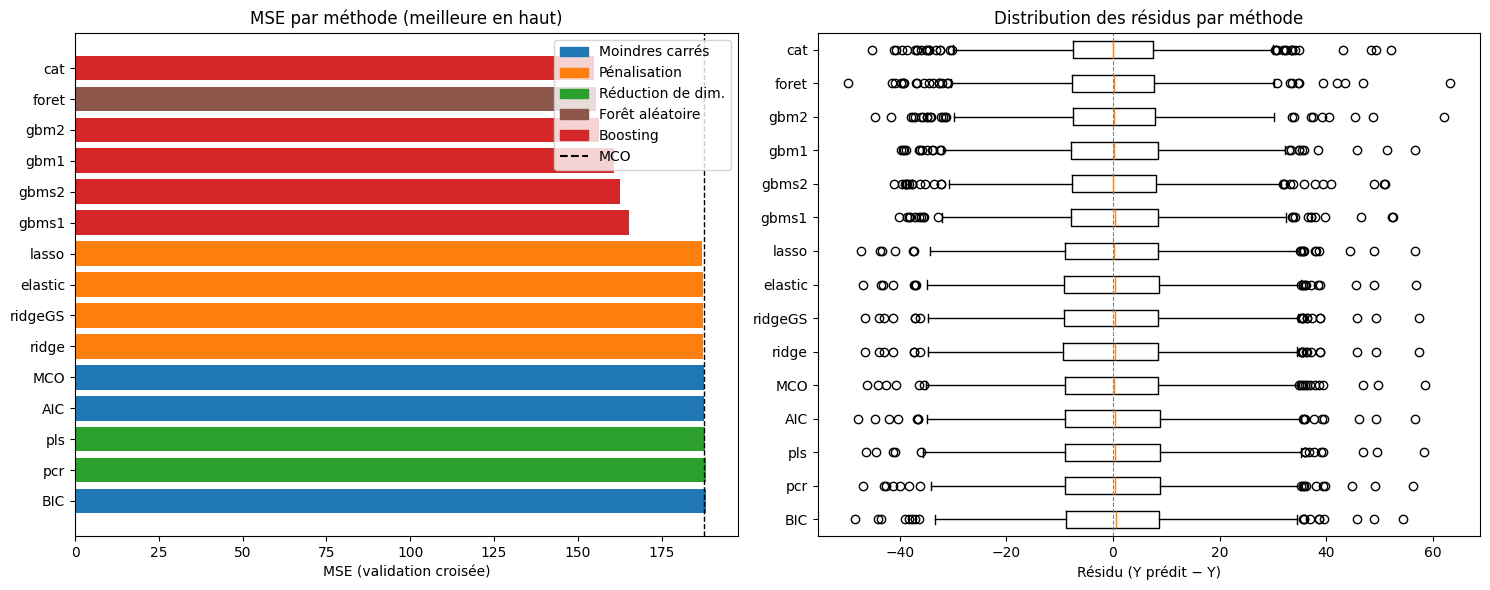

In [5]:
couleurs_famille = {"Moindres carrés": "tab:blue", "Pénalisation": "tab:orange", "Réduction de dim.": "tab:green",
                    "Forêt aléatoire": "tab:brown", "Boosting": "tab:red"}
ordre = metriques.index.tolist()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

ax1.barh(ordre, metriques["MSE"], color=[couleurs_famille[f] for f in metriques["Famille"]])
ax1.invert_yaxis()
ax1.axvline(metriques.loc["MCO", "MSE"], color="black", linestyle="--", linewidth=1, label="MCO")
ax1.set_xlabel("MSE (validation croisée)")
ax1.set_title("MSE par méthode (meilleure en haut)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in couleurs_famille.values()]
ax1.legend(handles + [plt.Line2D([0], [0], color="black", linestyle="--")], list(couleurs_famille) + ["MCO"], loc="upper right")

ax2.boxplot([residus[m].values for m in ordre], tick_labels=ordre, vert=False)
ax2.invert_yaxis()
ax2.axvline(0, color="grey", linestyle="--", linewidth=0.8)
ax2.set_xlabel("Résidu (Y prédit − Y)")
ax2.set_title("Distribution des résidus par méthode")

plt.tight_layout()
plt.savefig(DOSSIER_SORTIE + "resultats_reg_mse_residus.png", dpi=150)
plt.show()

### 4.3 Hyperparamètres choisis par bloc
Variabilité des réglages d'un bloc à l'autre : λ du lasso, nombre de composantes (PCR/PLS), nombre de variables retenues (BIC/AIC) et nombre d'itérations retenues par l'early stopping (boosting). Un réglage très variable signale un modèle instable.

In [6]:
hyper = pd.DataFrame(params_cv)
hyper.index = [f"bloc {i}" for i in range(len(hyper))]
resume = pd.DataFrame({"moyenne": hyper.mean(), "ecart_type": hyper.std(ddof=0)})
resume["CV_%"] = 100 * resume["ecart_type"] / resume["moyenne"]

display(hyper.round(3))
display(resume.round(3))

,nb_var_BIC,nb_var_AIC,lambda_lasso,nb_comp_pcr,nb_comp_pls,nb_iter_gbm1,nb_iter_gbm2,nb_iter_gbms1,nb_iter_gbms2,nb_iter_cat
bloc 0,6,9,0.236,19,8,124,62,73,44,106
bloc 1,6,10,0.097,19,11,154,72,82,54,87
bloc 2,5,9,0.270,19,12,107,66,59,48,81
bloc 3,6,10,0.101,19,13,192,99,61,58,147
bloc 4,5,7,0.104,19,12,123,72,116,54,101
bloc 5,5,9,0.127,16,7,129,80,68,63,72
bloc 6,5,11,0.110,19,11,98,62,62,56,42
bloc 7,5,11,0.102,19,9,110,62,74,41,115
bloc 8,5,8,0.138,15,12,108,62,80,46,59
bloc 9,5,10,0.088,19,12,137,73,67,49,68


,moyenne,ecart_type,CV_%
nb_var_BIC,5.300,0.458,8.646
nb_var_AIC,9.400,1.200,12.766
lambda_lasso,0.137,0.060,43.675
nb_comp_pcr,18.300,1.418,7.747
nb_comp_pls,10.700,1.900,17.757
nb_iter_gbm1,128.200,26.381,20.578
nb_iter_gbm2,71.000,11.045,15.557
nb_iter_gbms1,74.200,15.772,21.256
nb_iter_gbms2,51.300,6.497,12.665
nb_iter_cat,87.800,28.923,32.942


### 4.4 Évaluation sur l'échantillon de test final (si `TAILLE_TEST_FINAL > 0`)
Chaque modèle est réajusté sur **toutes** les observations de la validation croisée (hyperparamètres choisis par validation croisée interne, comme dans chaque bloc), puis évalué **une seule fois** sur le test final, resté à l'écart de toute sélection.
- **MSE_test** est l'estimation non biaisée de la performance du modèle retenu ; l'écart avec **MSE_cv** mesure l'optimisme dû au choix de la meilleure méthode sur les mêmes prédictions.
- Les intervalles de confiance (bootstrap des erreurs de test) donnent l'ordre de grandeur de l'incertitude : l'échantillon de test est petit, des méthodes aux intervalles qui se recouvrent ne sont pas départageables.

In [7]:
if est_test.any():
    ordre_cv = metriques.index
    res_test = PREV_test[methodes].sub(PREV_test["Y"], axis=0)[ordre_cv]
    tirages = np.random.default_rng(GRAINE).integers(0, len(res_test), size=(N_BOOT_IC, len(res_test)))
    mse_boot = np.array([(res_test[m].to_numpy()[tirages] ** 2).mean(axis=1) for m in ordre_cv])

    test_final = pd.DataFrame(index=ordre_cv)
    test_final["Famille"] = metriques["Famille"]
    test_final["Rang_cv"] = metriques["Rang"]
    test_final["MSE_cv"] = metriques["MSE"]
    test_final["MSE_test"] = (res_test ** 2).mean()
    test_final["IC95_bas"] = np.quantile(mse_boot, 0.025, axis=1)
    test_final["IC95_haut"] = np.quantile(mse_boot, 0.975, axis=1)
    test_final["Rang_test"] = test_final["MSE_test"].rank(method="min").astype(int)
    test_final["RMSE_test"] = np.sqrt(test_final["MSE_test"])
    test_final["MAE_test"] = res_test.abs().mean()
    test_final["Gain_vs_MCO_%"] = 100 * (test_final["MSE_test"] / test_final.loc["MCO", "MSE_test"] - 1)
    print(f"Test final : {len(res_test)} observations (modèles ajustés sur {n_cv} observations)")
    display(test_final.round(3))
    display(pd.Series(params_test, name="réglage du modèle final").to_frame().round(4))

    pos = np.arange(len(ordre_cv))
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(pos - 0.2, test_final["MSE_test"], height=0.4, color=[couleurs_famille[f] for f in test_final["Famille"]],
            xerr=[test_final["MSE_test"] - test_final["IC95_bas"], test_final["IC95_haut"] - test_final["MSE_test"]],
            error_kw=dict(ecolor="black", capsize=2, lw=1))
    ax.barh(pos + 0.2, test_final["MSE_cv"], height=0.4, color="lightgrey", edgecolor="grey")
    ax.set_yticks(pos)
    ax.set_yticklabels(ordre_cv)
    ax.invert_yaxis()
    ax.set_xlabel("MSE")
    ax.set_title("Test final (± IC95, couleur) vs validation croisée (gris) — méthodes classées par MSE de CV")
    plt.tight_layout()
    plt.savefig(DOSSIER_SORTIE + "resultats_reg_test_final.png", dpi=150)
    plt.show()
else:
    print("Pas de test final (TAILLE_TEST_FINAL = 0).")

Pas de test final (TAILLE_TEST_FINAL = 0).


## 5. Export des fichiers et synthèse

In [8]:
PREV.to_csv(DOSSIER_SORTIE + "PREV_complet.csv", index=False)
metriques.round(4).to_csv(DOSSIER_SORTIE + "metriques_reg.csv")
hyper.to_csv(DOSSIER_SORTIE + "hyperparametres_reg.csv")
if est_test.any():
    PREV_test.assign(bloc="test").to_csv(DOSSIER_SORTIE + "PREV_cvtest.csv", index=False)
    test_final.round(4).to_csv(DOSSIER_SORTIE + "metriques_reg_test_final.csv")

meilleur = metriques.index[0]
print(f"Espace de variables : {ESPACE} ({X.shape[1]} variables), {NB_BLOCS} blocs")
print(f"Meilleure méthode : {meilleur} (MSE = {metriques.loc[meilleur, 'MSE']:.2f}, RMSE = {metriques.loc[meilleur, 'RMSE']:.2f})")
print(f"MCO : MSE = {metriques.loc['MCO', 'MSE']:.2f} -> gain de {-metriques.loc[meilleur, 'Gain_vs_MCO_%']:.1f} % avec {meilleur}")
print("Top 3 :", ", ".join(f"{m} ({metriques.loc[m, 'MSE']:.2f})" for m in metriques.index[:3]))
print("\nFichiers écrits : PREV_complet.csv, metriques_reg.csv, hyperparametres_reg.csv, resultats_reg_mse_residus.png")
if est_test.any():
    print("Test final : PREV_cvtest.csv, metriques_reg_test_final.csv, resultats_reg_test_final.png")

Espace de variables : X (21 variables), 10 blocs
Meilleure méthode : cat (MSE = 154.87, RMSE = 12.44)
MCO : MSE = 187.51 -> gain de 17.4 % avec cat
Top 3 : cat (154.87), foret (155.28), gbm2 (156.31)

Fichiers écrits : PREV_complet.csv, metriques_reg.csv, hyperparametres_reg.csv, resultats_reg_mse_residus.png
